# Normalización y estandarización de datos médicos con CRISP DM

![Logo del instituto](img/ITQ.png)

**Ejercicio practico:** En este ejercicio vamos a aplicar todo lo aprendido de Normalización y estandarización de datos médicos con CRISP DM 

**Nombre:** Leticia Verdezoto

**Fecha:** 09-11-2026

**Link:** [Link Repositorio](https://github.com/verdezotoandivel-ctrl/Fundamentos-de-machine-Learning)



In [2]:
%pip install -q ucimlrepo pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sys
from datetime import datetime

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Fecha de ejecución/descarga:", datetime.now().astimezone().isoformat(timespec="seconds"))

Python: 3.13.18 | packaged by Anaconda, Inc. | (main, Oct 27 2026, 00:53:21) [MSC v.1942 64 bit (AMD64)]
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1
Fecha de ejecución/descarga: 2026-11-09T17:50:02-05:00


**Importación de librerías y verificación del entorno**
En esta celda importamos todas las librerías que vamos a usar en el ejercicio, pandas para manejar los datos, numpy para cálculos, matplotlib y seaborn para los gráficos, sklearn para el Machine Learning y fetch_ucirepo para descargar el dataset.
Además se verifica las versiones instaladas para dejar constancia de que el entorno es reproducible.

In [4]:
dataset = fetch_ucirepo(id=296)
df_original = dataset.data.original.copy()

print("Dimensiones originales (filas, columnas):", df_original.shape)
print("Número de filas:", len(df_original))
assert len(df_original) > 100_000, "El dataset debe superar los 100 000 registros."

display(df_original.head())
display(dataset.variables)

# Guardar una copia local exacta del conjunto descargado
df_original.to_csv("hospitalizaciones_diabetes_original.csv", index=False)
print("Copia original guardada.")

C:\Users\Usuario\anaconda3\envs\Fundamentos_de_Machine_Learning\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Dimensiones originales (filas, columnas): (101766, 50)
Número de filas: 101766


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


Copia original guardada.


**Descripción del problema**

El equipo hospitalario desea explorar cómo se distribuyen las características de las hospitalizaciones de pacientes con diabetes y cómo se relacionan descriptivamente con la readmisión. Antes de construir modelos, necesita conocer la calidad de los datos y preparar variables cuantitativas con escalas comparables.

Actores interesados
Personal de gestión hospitalaria: puede consultar patrones agregados de hospitalización y readmisión.
Personal clínico: puede interpretar el contexto asistencial, sin usar este análisis como diagnóstico.
Equipo de análisis de datos: revisa calidad, estructura y transformaciones.

La exploración de los datos antes de construir modelos es necesaria para conocer la calidad de la información, identificar valores faltantes, detectar registros duplicados, comprender las variables y analizar sus distribuciones.

**Objetivo general**

Analizar descriptivamente el conjunto Diabetes 130-US Hospitals for Years 1999–2008, documentar su calidad y preparar siete variables cuantitativas mediante Min-Max y Z-score.

¿Cómo se distribuyen las siete variables cuantitativas seleccionadas?


¿Qué proporción de registros corresponde a cada categoría de readmitted?


¿Qué valores faltantes, duplicados y posibles valores atípicos aparecen en los datos?


¿Cómo cambian las escalas de las variables después de Min-Max y Z-score?

La descarga contiene más de 100 000 filas.
Se documentan dimensiones, columnas, faltantes y duplicados.
Se generan al menos cuatro visualizaciones y se analizan valores atípicos en dos variables.
Se transforman las siete variables indicadas y se verifican sus rangos/estadísticas.
Se exportan dos CSV manteniendo el mismo orden de filas.

**Variable de referencia readmitted**

La variable readmitted distingue las categorías NO, <30 y >30. NO indica que no hubo readmisión registrada en el periodo definido por el conjunto; <30 indica readmisión en menos de 30 días; >30 indica readmisión después de 30 días.

**Limitaciones**

Los datos corresponden a hospitales de Estados Unidos entre 1999 y 2008. No representan necesariamente la atención actual ni a toda la población. Una persona puede aparecer en varias filas por distintas hospitalizaciones. Los identificadores no se usan para intentar identificar personasonas.



In [5]:
# Comprobar que existe la variable de referencia y revisar sus categorías
print("¿Existe readmitted?:", "readmitted" in df_original.columns)
if "readmitted" in df_original.columns:
    print(df_original["readmitted"].value_counts(dropna=False))

¿Existe readmitted?: True
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [6]:
print("Filas (hospitalizaciones):", len(df_original))
if "patient_nbr" in df_original.columns:
    print("Identificadores de paciente distintos:", df_original["patient_nbr"].nunique(dropna=True))
if "encounter_id" in df_original.columns:
    print("Identificadores de encuentro distintos:", df_original["encounter_id"].nunique(dropna=True))

Filas (hospitalizaciones): 101766
Identificadores de paciente distintos: 71518
Identificadores de encuentro distintos: 101766


**Paso 3. Fase 2: Comprensión de los datos**

encounter_id identifica el encuentro/hospitalización y patient_nbr identifica al paciente dentro del conjunto. El número de filas es el número de hospitalizaciones; el número de patient_nbr distintos es el número de identificadores de paciente distintos observados.

In [7]:
variables_uci = dataset.variables.copy()
display(variables_uci)

# Diccionario complementario generado a partir de las columnas reales
diccionario = pd.DataFrame({
    "nombre": df_original.columns,
    "tipo_observado": [str(df_original[c].dtype) for c in df_original.columns],
    "valores_no_nulos": [int(df_original[c].notna().sum()) for c in df_original.columns],
    "valores_distintos": [int(df_original[c].nunique(dropna=True)) for c in df_original.columns],
})
display(diccionario)
diccionario.to_csv("diccionario_columnas_observado.csv", index=False)

,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


,nombre,tipo_observado,valores_no_nulos,valores_distintos
0,encounter_id,int64,101766,101766
1,patient_nbr,int64,101766,71518
2,race,str,99493,5
3,gender,str,101766,3
4,age,str,101766,10
5,weight,str,3197,9
6,admission_type_id,int64,101766,8
7,discharge_disposition_id,int64,101766,26
8,admission_source_id,int64,101766,17
9,time_in_hospital,int64,101766,14


**Diccionario de todas las columnas**

La tabla de UCI se utiliza como diccionario de variables. El tipo observado se obtiene de pandas; el tipo conceptual y el rol analítico se asignan como orientación y deben revisarse contra la descripción oficial. Un código almacenado como número puede representar una categoría, no una medición.

In [8]:
faltantes = pd.DataFrame({
    "nulos_pandas": df_original.isna().sum(),
    "marcador_?": (df_original.astype("string") == "?").sum(),
})
faltantes["total_faltantes_identificados"] = faltantes["nulos_pandas"] + faltantes["marcador_?"]
faltantes["porcentaje_sobre_filas"] = 100 * faltantes["total_faltantes_identificados"] / len(df_original)
display(faltantes.sort_values("porcentaje_sobre_filas", ascending=False))
print("Frecuencia del texto 'None' por columna:")
display((df_original.astype("string") == "None").sum().sort_values(ascending=False).head(20))

,nulos_pandas,marcador_?,total_faltantes_identificados,porcentaje_sobre_filas
weight,98569,0,98569,96.858479
max_glu_serum,96420,0,96420,94.746772
A1Cresult,84748,0,84748,83.277322
medical_specialty,49949,0,49949,49.082208
payer_code,40256,0,40256,39.557416
race,2273,0,2273,2.233555
diag_3,1423,0,1423,1.398306
diag_2,358,0,358,0.351787
diag_1,21,0,21,0.020636
patient_nbr,0,0,0,0.0


Frecuencia del texto 'None' por columna:


encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
dtype: Int64

**Datos faltantes y marcadores**

En este conjunto, el marcador ? se utiliza para representar valores faltantes. Se calcula el número y porcentaje de ? y de nulos reales antes de convertir ? a NaN. La categoría textual None, cuando aparece como valor de una columna, se conserva hasta comprobar su significado en el diccionario; no se convierte automáticamente en nulo.

In [12]:
print("Filas completamente duplicadas:", int(df_original.duplicated().sum()))
for col in ["encounter_id", "patient_nbr"]:
    if col in df_original.columns:
        print(f"{col}: filas={df_original[col].notna().sum()}, únicos={df_original[col].nunique(dropna=True)}, repetidos={df_original[col].duplicated().sum()}")

Filas completamente duplicadas: 0
encounter_id: filas=101766, únicos=101766, repetidos=0
patient_nbr: filas=101766, únicos=71518, repetidos=30248


**Duplicados e identificadores**

Se cuentan filas completamente duplicadas y repeticiones de identificadores. No se eliminan automáticamente las filas con el mismo patient_nbr: pueden representar hospitalizaciones válidas de una misma persona.

In [13]:
variables = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
]

faltan_columnas = [c for c in variables if c not in df_original.columns]
if faltan_columnas:
    raise ValueError(f"Faltan columnas requeridas en el dataset: {faltan_columnas}")

# Copia de trabajo: el marcador ? pasa a NaN, sin modificar df_original
df_trabajo = df_original.copy().replace("?", np.nan)

for c in variables:
    df_trabajo[c] = pd.to_numeric(df_trabajo[c], errors="coerce")

estadisticas_iniciales = df_trabajo[variables].describe().T
estadisticas_iniciales = estadisticas_iniciales.rename(columns={
    "min": "mínimo", "max": "máximo", "mean": "media",
    "std": "desviación_estándar", "25%": "Q1", "50%": "mediana", "75%": "Q3"
})
display(estadisticas_iniciales)
if "readmitted" in df_trabajo.columns:
    print("Frecuencias de readmitted:")
    display(df_trabajo["readmitted"].value_counts(dropna=False).to_frame("frecuencia"))
    display((df_trabajo["readmitted"].value_counts(normalize=True, dropna=False) * 100).to_frame("porcentaje"))

,count,media,desviación_estándar,mínimo,Q1,mediana,Q3,máximo
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0


Frecuencias de readmitted:


,frecuencia
readmitted,
NO,54864
>30,35545
<30,11357


,porcentaje
readmitted,
NO,53.911916
>30,34.928169
<30,11.159916


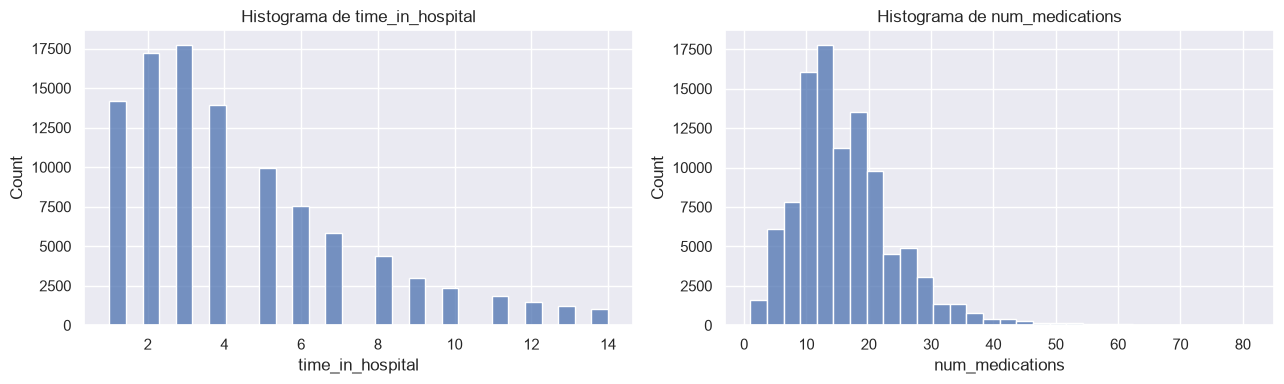

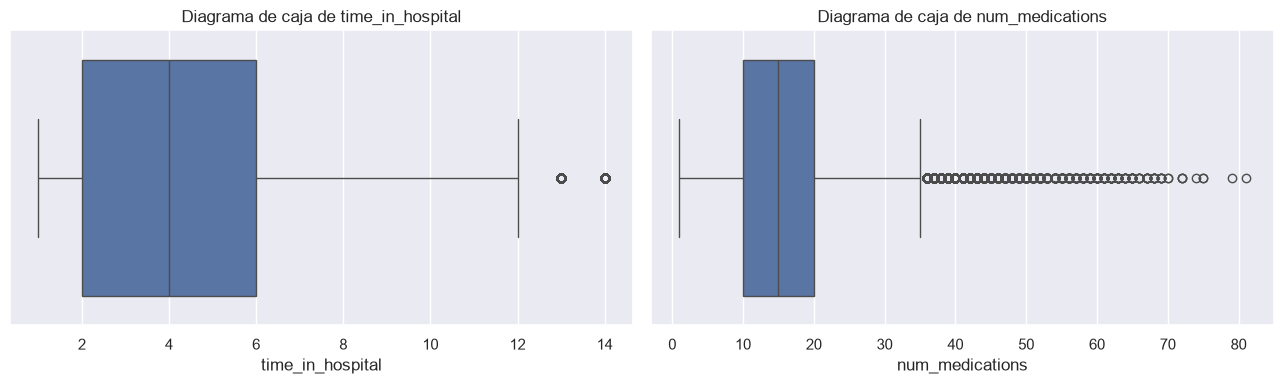

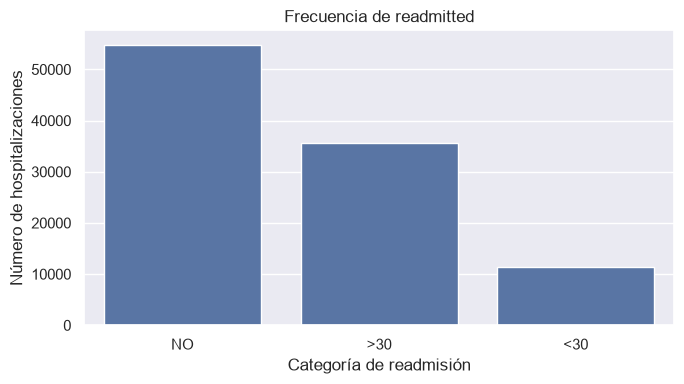

In [14]:
# Histogramas de dos variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["time_in_hospital", "num_medications"]):
    sns.histplot(data=df_trabajo, x=col, bins=30, ax=ax)
    ax.set_title(f"Histograma de {col}")
plt.tight_layout()
plt.show()

# Diagramas de caja de las mismas dos variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["time_in_hospital", "num_medications"]):
    sns.boxplot(data=df_trabajo, x=col, ax=ax)
    ax.set_title(f"Diagrama de caja de {col}")
plt.tight_layout()
plt.show()

# Frecuencia de readmitted
plt.figure(figsize=(7, 4))
orden = ["NO", ">30", "<30"]
sns.countplot(data=df_trabajo, x="readmitted", order=orden)
plt.title("Frecuencia de readmitted")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.tight_layout()
plt.show()

**Análisis:**

El histograma muestra la cantidad de días que permanecieron hospitalizados los pacientes, la mayor concentración de registros se encuentra entre 1 y 4 días. A medida que aumentan los días de hospitalización, la frecuencia disminuye.

La distribución presenta asimetría positiva, porque hay más registros en los valores bajos y una cola hacia los valores altos, esto indica que existen menos pacientes con estancias hospitalarias prolongadas.

La mayoría de los pacientes permaneció hospitalizada durante pocos días.

**Histograma de num_medications**

La gráfica muestra la cantidad de medicamentos administrados durante cada hospitalización, la mayor concentración se encuentra aproximadamente entre 10 y 20 medicamentos.

A partir de los 20 medicamentos, la frecuencia comienza a disminuir, se observa una cola hacia la derecha, con algunos registros que superan los 40 medicamentos y llegan aproximadamente a 80.

Esto indica que la distribución tiene asimetría positiva y que existen valores extremos.

La mayoría de las hospitalizaciones registra entre 10 y 20 medicamentos, mientras que una cantidad menor presenta valores elevados.

**Diagrama de caja de time_in_hospital**

El diagrama de caja permite observar la distribución de los días de hospitalización.
- La mediana se encuentra aproximadamente en 4 días.
- El 50 % central de los registros está entre 2 y 6 días.
- Los valores habituales llegan aproximadamente hasta los 12 días.
- Se observan valores atípicos alrededor de 13 y 14 días.
La mayoría de los pacientes tiene estancias hospitalarias cortas. Los valores atípicos representan hospitalizaciones más prolongadas que el comportamiento habitual de los datos.

**Diagrama de caja de num_medications**

El diagrama muestra una concentración de datos entre aproximadamente 10 y 20 medicamentos.
- La mediana se encuentra alrededor de 14 medicamentos.
- El 50 % central de los registros está entre 10 y 20 medicamentos.
- Se observan valores atípicos a partir de aproximadamente 36 medicamentos.
- Algunos registros alcanzan valores mayores a 80.
La presencia de tantos valores atípicos indica que existe una diferencia considerable entre la cantidad de medicamentos registrada en la mayoría de las hospitalizaciones y algunos casos particulares.

La variable presenta valores extremos que pueden influir en los resultados de los métodos de escalamiento.

**Gráfica de frecuencia de readmitted**

Esta gráfica representa la cantidad de hospitalizaciones según la categoría de readmisión.

Se observan tres categorías:

NO: Es la categoría con mayor frecuencia, con aproximadamente 54.000 registros. Representa hospitalizaciones sin readmisión registrada. >30: Tiene aproximadamente 36.000 registros. Representa pacientes readmitidos después de 30 días.

<30: Esta distribución muestra que las categorías no tienen la misma cantidad de registros.



In [15]:
def resumen_iqr(serie):
    s = serie.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    mascara = (s < inferior) | (s > superior)
    return {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "limite_inferior": inferior, "limite_superior": superior,
        "cantidad_atipicos": int(mascara.sum()),
        "porcentaje_atipicos": float(mascara.mean() * 100),
    }

tabla_iqr = pd.DataFrame({
    c: resumen_iqr(df_trabajo[c]) for c in ["number_outpatient", "number_inpatient"]
}).T
display(tabla_iqr)

,Q1,Q3,IQR,limite_inferior,limite_superior,cantidad_atipicos,porcentaje_atipicos
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739.0,16.448519
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049.0,6.926675


El método del Rango Intercuartílico (IQR) detecta valores atípicos (outliers) calculando la dispersión del 50% central de los datos y estableciendo límites de corte (o barreras de Tukey).

In [16]:
filas_antes = len(df_trabajo)
nulos_antes = df_trabajo[variables].isna().sum()

# Mantener el índice original para poder rastrear las filas
df_limpio = df_trabajo.dropna(subset=variables).copy()

registro_limpieza = pd.DataFrame([
    {"decisión": "Copia de trabajo y reemplazo de ? por NaN", "filas_antes": filas_antes,
     "filas_despues": len(df_trabajo), "filas_eliminadas": 0},
    {"decisión": "Eliminar filas con faltantes en las siete variables de escalamiento",
     "filas_antes": len(df_trabajo), "filas_despues": len(df_limpio),
     "filas_eliminadas": len(df_trabajo) - len(df_limpio)}
])
display(pd.DataFrame({"nulos_antes_de_filtrar": nulos_antes}))
display(registro_limpieza)

print("Filas originales:", len(df_original))
print("Filas limpias para escalar:", len(df_limpio))
print("Columnas originales:", df_original.shape[1])
print("Columnas de escalamiento:", len(variables))
print("Índice conservado:", df_limpio.index.is_unique)

# Copia numérica limpia previa a cualquier transformación
X_limpio = df_limpio[variables].copy()
X_limpio.to_csv("variables_numericas_limpias.csv", index=True, index_label="indice_original")
display(X_limpio.head())

,nulos_antes_de_filtrar
time_in_hospital,0
num_lab_procedures,0
num_procedures,0
num_medications,0
number_outpatient,0
number_emergency,0
number_inpatient,0


,decisión,filas_antes,filas_despues,filas_eliminadas
0,Copia de trabajo y reemplazo de ? por NaN,101766,101766,0
1,Eliminar filas con faltantes en las siete vari...,101766,101766,0


Filas originales: 101766
Filas limpias para escalar: 101766
Columnas originales: 50
Columnas de escalamiento: 7
Índice conservado: True


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


In [17]:
print("Variables incluidas:", variables)
print("Identificadores excluidos:", [c for c in ["encounter_id", "patient_nbr"] if c in df_original.columns])
print("Códigos categóricos excluidos:", [c for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"] if c in df_original.columns])
print("age excluida por intervalos:", "age" in df_original.columns)

Variables incluidas: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']
Identificadores excluidos: ['encounter_id', 'patient_nbr']
Códigos categóricos excluidos: ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
age excluida por intervalos: True


In [18]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler(feature_range=(0, 1))
X_minmax = pd.DataFrame(
    minmax.fit_transform(X_limpio),
    columns=variables,
    index=X_limpio.index
)

print("Primeras diez filas normalizadas:")
display(X_minmax.head(10))

comparacion_minmax = pd.DataFrame({
    "mínimo_antes": X_limpio.min(),
    "máximo_antes": X_limpio.max(),
    "mínimo_despues": X_minmax.min(),
    "máximo_despues": X_minmax.max(),
})
display(comparacion_minmax)

tol = 1e-9
print("¿Todos los valores están dentro de [0, 1]?:",
      bool((X_minmax.to_numpy() >= -tol).all() and (X_minmax.to_numpy() <= 1 + tol).all()))
print("Columnas constantes en entrada:", X_limpio.columns[X_limpio.nunique() <= 1].tolist())

Primeras diez filas normalizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


,mínimo_antes,máximo_antes,mínimo_despues,máximo_despues
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


¿Todos los valores están dentro de [0, 1]?: True
Columnas constantes en entrada: []


La transformación lleva los mínimos observados a 0 y los máximos a 1. Los valores extremos pueden comprimir gran parte de las observaciones en una zona pequeña del intervalo. Si una columna es constante, el denominador de la fórmula sería cero; MinMaxScaler evita la división por cero y transforma esa columna constante en 0 dentro del conjunto.

In [19]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()
X_zscore = pd.DataFrame(
    standard.fit_transform(X_limpio),
    columns=variables,
    index=X_limpio.index
)

print("Primeras diez filas estandarizadas:")
display(X_zscore.head(10))

verificacion_z = pd.DataFrame({
    "media": X_zscore.mean(),
    "desviacion_ddof0": X_zscore.std(ddof=0),
})
display(verificacion_z)

tol_media = 1e-8
tol_std = 1e-8
print("¿Medias aproximadamente 0?:", bool(np.allclose(X_zscore.mean().to_numpy(), 0, atol=tol_media)))
print("¿Desviaciones ddof=0 aproximadamente 1 o 0 si constante?:",
      bool(np.allclose(X_zscore.std(ddof=0).to_numpy(),
                       np.where(X_limpio.nunique().to_numpy() <= 1, 0, 1),
                       atol=tol_std)))
print("Mínimo global Z-score:", X_zscore.min().min())
print("Máximo global Z-score:", X_zscore.max().max())

Primeras diez filas estandarizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


,media,desviacion_ddof0
time_in_hospital,5.809126e-17,1.0
num_lab_procedures,1.161825e-16,1.0
num_procedures,-6.479410e-17,1.0
num_medications,-1.340568e-16,1.0
number_outpatient,3.574847e-17,1.0
number_emergency,1.787424e-17,1.0
number_inpatient,-3.574847e-17,1.0


¿Medias aproximadamente 0?: True
¿Desviaciones ddof=0 aproximadamente 1 o 0 si constante?: True
Mínimo global Z-score: -2.1396295988863177
Máximo global Z-score: 81.46673339595054


La estandarización centra cada variable alrededor de 0 y expresa los valores en unidades de desviación estándar. Pueden aparecer valores negativos porque una observación puede estar por debajo de la media. También pueden aparecer valores mayores que 1 o menores que −1; Z-score no limita los datos al intervalo [0, 1]. Para una columna constante.

In [20]:
def resumen_transformacion(datos, nombre):
    salida = datos.agg(["min", "max", "mean"])
    salida.loc["std_ddof0"] = datos.std(ddof=0)
    salida.index = pd.MultiIndex.from_product([[nombre], salida.index], names=["versión", "estadística"])
    return salida

tabla_comparacion = pd.concat([
    resumen_transformacion(X_limpio, "Original limpio"),
    resumen_transformacion(X_minmax, "Min-Max"),
    resumen_transformacion(X_zscore, "Z-score"),
])
display(tabla_comparacion)
tabla_comparacion.to_csv("tabla_comparacion_estadistica.csv")

time_in_hospital  num_lab_procedures  \
versión         estadística                                         
Original limpio min              1.000000e+00        1.000000e+00   
                max              1.400000e+01        1.320000e+02   
                mean             4.395987e+00        4.309564e+01   
                std_ddof0        2.985093e+00        1.967427e+01   
Min-Max         min              0.000000e+00        0.000000e+00   
                max              1.000000e+00        1.000000e+00   
                mean             2.612298e-01        3.213408e-01   
                std_ddof0        2.296225e-01        1.501852e-01   
Z-score         min             -1.137649e+00       -2.139630e+00   
                max              3.217324e+00        4.518815e+00   
                mean             5.809126e-17        1.161825e-16   
                std_ddof0        1.000000e+00        1.000000e+00   

                             num_procedures  num_medications  \
versión         estadística                                    
Original limpio min            0.000000e+00     1.000000e+00   
                max            6.000000e+00     8.100000e+01   
                mean           1.339730e+00     1.602184e+01   
                std_ddof0      1.705799e+00     8.127526e+00   
Min-Max         min            0.000000e+00     0.000000e+00   
                max            1.000000e+00     1.000000e+00   
                mean           2.232884e-01     1.877731e-01   
                std_ddof0      2.842998e-01     1.015941e-01   
Z-score         min           -7.853977e-01    -1.848268e+00   
                max            2.732016e+00     7.994826e+00   
                mean          -6.479410e-17    -1.340568e-16   
                std_ddof0      1.000000e+00     1.000000e+00   

                             number_outpatient  number_emergency  \
versión         estadística                                        
Original limpio min               0.000000e+00      0.000000e+00   
                max               4.200000e+01      7.600000e+01   
                mean              3.693572e-01      1.978362e-01   
                std_ddof0         1.267259e+00      9.304677e-01   
Min-Max         min               0.000000e+00      0.000000e+00   
                max               1.000000e+00      1.000000e+00   
                mean              8.794218e-03      2.603108e-03   
                std_ddof0         3.017283e-02      1.224300e-02   
Z-score         min              -2.914615e-01     -2.126202e-01   
                max               3.285094e+01      8.146673e+01   
                mean              3.574847e-17      1.787424e-17   
                std_ddof0         1.000000e+00      1.000000e+00   

                             number_inpatient  
versión         estadística                    
Original limpio min              0.000000e+00  
                max              2.100000e+01  
                mean             6.355659e-01  
                std_ddof0        1.262857e+00  
Min-Max         min              0.000000e+00  
                max              1.000000e+00  
                mean             3.026504e-02  
                std_ddof0        6.013605e-02  
Z-score         min             -5.032762e-01  
                max              1.612568e+01  
                mean            -3.574847e-17  
                std_ddof0        1.000000e+00

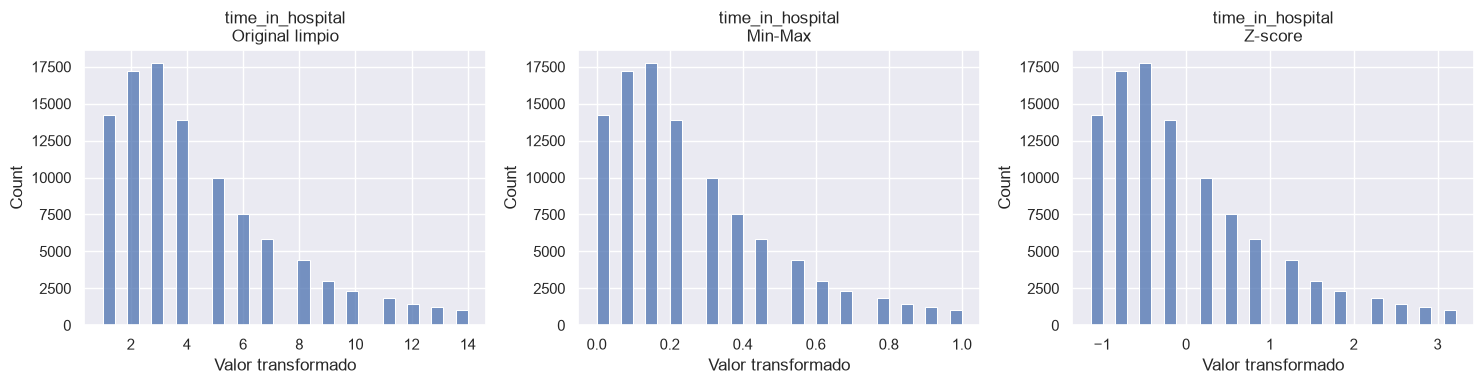

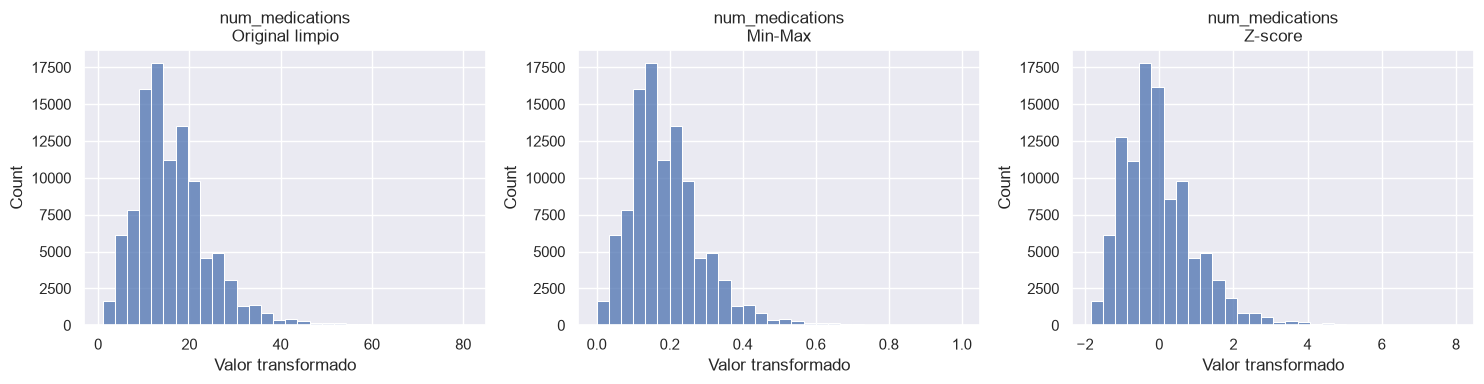

In [21]:
for col in ["time_in_hospital", "num_medications"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    versiones = [
        ("Original limpio", X_limpio[col]),
        ("Min-Max", X_minmax[col]),
        ("Z-score", X_zscore[col]),
    ]
    for ax, (nombre, serie) in zip(axes, versiones):
        sns.histplot(serie, bins=30, ax=ax)
        ax.set_title(f"{col}\n{nombre}")
        ax.set_xlabel("Valor transformado")
    plt.tight_layout()
    plt.show()

La transformación lineal cambia la escala, pero conserva el orden de los valores y la forma general de la distribución. Se muestran las tres versiones para time_in_hospital y num_medications.

In [22]:
col = "time_in_hospital"
cinco = X_limpio[col].head(5)
xmin = X_limpio[col].min()
xmax = X_limpio[col].max()
media = X_limpio[col].mean()
sigma = X_limpio[col].std(ddof=0)

manual = pd.DataFrame({"x_original": cinco})
manual["minmax_manual"] = (manual["x_original"] - xmin) / (xmax - xmin) if xmax != xmin else 0.0
manual["zscore_manual"] = (manual["x_original"] - media) / sigma if sigma != 0 else 0.0
manual["minmax_sklearn"] = X_minmax.loc[cinco.index, col]
manual["zscore_sklearn"] = X_zscore.loc[cinco.index, col]

print(f"Parámetros Min-Max: mínimo={xmin}, máximo={xmax}")
print(f"Parámetros Z-score: media={media}, desviación ddof=0={sigma}")
display(manual)
print("Coincide Min-Max:", np.allclose(manual["minmax_manual"], manual["minmax_sklearn"]))
print("Coincide Z-score:", np.allclose(manual["zscore_manual"], manual["zscore_sklearn"]))

Parámetros Min-Max: mínimo=1, máximo=14
Parámetros Z-score: media=4.395986871843248, desviación ddof=0=2.985093100907283


,x_original,minmax_manual,zscore_manual,minmax_sklearn,zscore_sklearn
0,1,0.000000,-1.137649,0.000000,-1.137649
1,3,0.153846,-0.467653,0.153846,-0.467653
2,2,0.076923,-0.802651,0.076923,-0.802651
3,2,0.076923,-0.802651,0.076923,-0.802651
4,1,0.000000,-1.137649,0.000000,-1.137649


Coincide Min-Max: True
Coincide Z-score: True


Se utiliza time_in_hospital. Se seleccionan cinco observaciones reales de la copia limpia y se aplican las fórmulas con mínimo, máximo, media y desviación poblacional (ddof=0) obtenidos de esa variable.

In [23]:
X_minmax.to_csv("datos_normalizados.csv", index=True, index_label="indice_original")
X_zscore.to_csv("datos_estandarizados.csv", index=True, index_label="indice_original")

print("Archivos exportados:")
print("- datos_normalizados.csv")
print("- datos_estandarizados.csv")
print("- tabla_comparacion_estadistica.csv")

# Comprobación de correspondencia
assert X_minmax.index.equals(X_limpio.index)
assert X_zscore.index.equals(X_limpio.index)
assert X_minmax.columns.tolist() == variables
assert X_zscore.columns.tolist() == variables
print("Comprobación de orden, índice y columnas: correcta.")

Archivos exportados:
- datos_normalizados.csv
- datos_estandarizados.csv
- tabla_comparacion_estadistica.csv
Comprobación de orden, índice y columnas: correcta.


Los dos archivos contienen las mismas siete columnas, el mismo orden de filas y el índice original como referencia.

**Preguntas de reflexión**

¿Por qué un código categórico numérico no debe escalarse como una medición?


Porque el número representa una etiqueta o categoría y no una cantidad. Escalarlo introduciría distancias numéricas que no tienen significado.

¿Cómo afectaría un valor extremo a Min-Max y a Z-score?


En Min-Max, un valor extremo puede ampliar el rango y comprimir la mayoría de los datos cerca de 0. En Z-score, un valor extremo puede desplazar la media y aumentar la desviación estándar, cambiando los puntajes de las demás observaciones.

¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?

Porque cada fila representa una hospitalización. Un paciente puede ingresar varias veces en fechas o episodios diferentes. La repetición de patient_nbr no significa que el registro esté duplicado.

¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?


Cambiar de escala modifica las unidades o el rango de los valores. No necesariamente cambia la asimetría.


¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?


Separaría primero los datos en entrenamiento y prueba. Ajustaría el escalador solo con entrenamiento y usaría transform para prueba. Si hay varias hospitalizaciones de una misma persona, utilizaría una separación por paciente para evitar que sus registros aparezcan en ambos grupos.
